In [1]:
import pickle, re, numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [2]:
NET_DIR  = r'E:\Claude\euclid-analysis\output\networks'
THM_DIR  = r'E:\Claude\euclid-analysis\output\initial_analysis'
CLS_PATH = rf'{THM_DIR}\final_classification.csv'

In [3]:
with open(f'{NET_DIR}/Human_Citation_Network.pkl', 'rb') as f:
    G_hu_full = pickle.load(f)

G_ai_full = {}
for run in ['RunA', 'RunB', 'RunC']:
    with open(f'{NET_DIR}/{run}_AI_Citation_Network_Final.pkl', 'rb') as f:
        G_ai_full[run] = pickle.load(f)

with open(f'{THM_DIR}/Human_Citation_Network_TheoremOnly.pkl', 'rb') as f:
    G_hu_thm = pickle.load(f)

G_ai_thm = {}
for run in ['RunA', 'RunB', 'RunC']:
    with open(f'{THM_DIR}/{run}_AI_Citation_Network_TheoremOnly.pkl', 'rb') as f:
        G_ai_thm[run] = pickle.load(f)

In [4]:
df_cls = pd.read_csv(CLS_PATH, dtype={'Proposition': str})
d_pairs = []
for _, row in df_cls.iterrows():
    for run in ['RunA', 'RunB', 'RunC']:
        if row[run] == 'D':
            d_pairs.append((run, row['Proposition']))
print(f"D-class pairs: {len(d_pairs)}")

D-class pairs: 379


In [5]:
def sort_key_thm(n):
    b, p = str(n).strip().split('.')
    return (int(b), int(p))

def is_theorem(n):
    return bool(re.fullmatch(r'\d+\.\d+', str(n).strip()))

all_thm_nodes = set(G_hu_thm.nodes())
for run in ['RunA', 'RunB', 'RunC']:
    all_thm_nodes |= set(G_ai_thm[run].nodes())
thm_sorted = sorted(all_thm_nodes, key=sort_key_thm)
thm_idx = {n: i for i, n in enumerate(thm_sorted)}

def build_full_idx(thm_idx, all_nodes):
    idx = dict(thm_idx)
    for n in all_nodes:
        ns = str(n).strip()
        if ns in idx:
            continue
        if re.fullmatch(r'P\d+', ns) or ns.startswith('CN'):
            idx[ns] = thm_idx.get('1.1', 0)
        elif ns.startswith('D'):
            m = re.match(r'D(\d+)\.', ns)
            if m:
                idx[ns] = thm_idx.get(f'{m.group(1)}.1', 0)
    return idx

all_full = set(G_hu_full.nodes())
for run in ['RunA', 'RunB', 'RunC']:
    all_full |= set(G_ai_full[run].nodes())
full_idx = build_full_idx(thm_idx, all_full)

def compute_distances(G, seq_idx):
    return [seq_idx[u] - seq_idx[v] for u, v in G.edges()
            if u in seq_idx and v in seq_idx and seq_idx[u] > seq_idx[v]]

hu_dist_full = compute_distances(G_hu_full, full_idx)
ai_dist_full = []
for run in ['RunA', 'RunB', 'RunC']:
    ai_dist_full.extend(compute_distances(G_ai_full[run], full_idx))

hu_dist_thm = compute_distances(G_hu_thm, thm_idx)
ai_dist_thm = []
for run in ['RunA', 'RunB', 'RunC']:
    ai_dist_thm.extend(compute_distances(G_ai_thm[run], thm_idx))

for label, hd, ad in [('Full', hu_dist_full, ai_dist_full),
                       ('Thm',  hu_dist_thm,  ai_dist_thm)]:
    print(f"{label}: Human mean={np.mean(hd):.1f} med={np.median(hd):.0f} n={len(hd)}, "
          f"AI mean={np.mean(ad):.1f} med={np.median(ad):.0f} n={len(ad)}")

Full: Human mean=86.3 med=38 n=1883, AI mean=111.2 med=61 n=10690
Thm: Human mean=89.2 med=35 n=1638, AI mean=102.5 med=44 n=6525


In [6]:
def compute_proportions(d_pairs, G_ai_dict, G_human):
    rows = []
    for run, prop in d_pairs:
        G_a = G_ai_dict[run]
        ai_direct = set(G_a.successors(prop)) if prop in G_a else set()
        hu_direct = set(G_human.successors(prop)) if prop in G_human else set()
        ai_only = ai_direct - hu_direct
        hu_only = hu_direct - ai_direct
        if not ai_only:
            continue
        hu_full_deps = (nx.descendants(G_human, prop) if prop in G_human else set()) | hu_direct
        hu_only_deps = set()
        for ref in hu_only:
            if ref in G_human:
                hu_only_deps |= nx.descendants(G_human, ref)
        hu_only_deps |= hu_only
        rows.append({
            'r_full':   sum(1 for r in ai_only if r in hu_full_deps) / len(ai_only),
            'r_huonly': sum(1 for r in ai_only if r in hu_only_deps) / len(ai_only),
        })
    return pd.DataFrame(rows)

print("Computing full network proportions...")
df_prop_full = compute_proportions(d_pairs, G_ai_full, G_hu_full)
print("Computing theorem-only proportions...")
df_prop_thm  = compute_proportions(d_pairs, G_ai_thm, G_hu_thm)

for label, df in [('Full', df_prop_full), ('Thm', df_prop_thm)]:
    print(f"{label} (n={len(df)}): "
          f"r_huonly mean={df['r_huonly'].mean():.3f} med={df['r_huonly'].median():.3f}, "
          f"r_full mean={df['r_full'].mean():.3f} med={df['r_full'].median():.3f}")

Computing full network proportions...
Computing theorem-only proportions...
Full (n=377): r_huonly mean=0.345 med=0.333, r_full mean=0.470 med=0.500
Thm (n=343): r_huonly mean=0.344 med=0.250, r_full mean=0.448 med=0.500


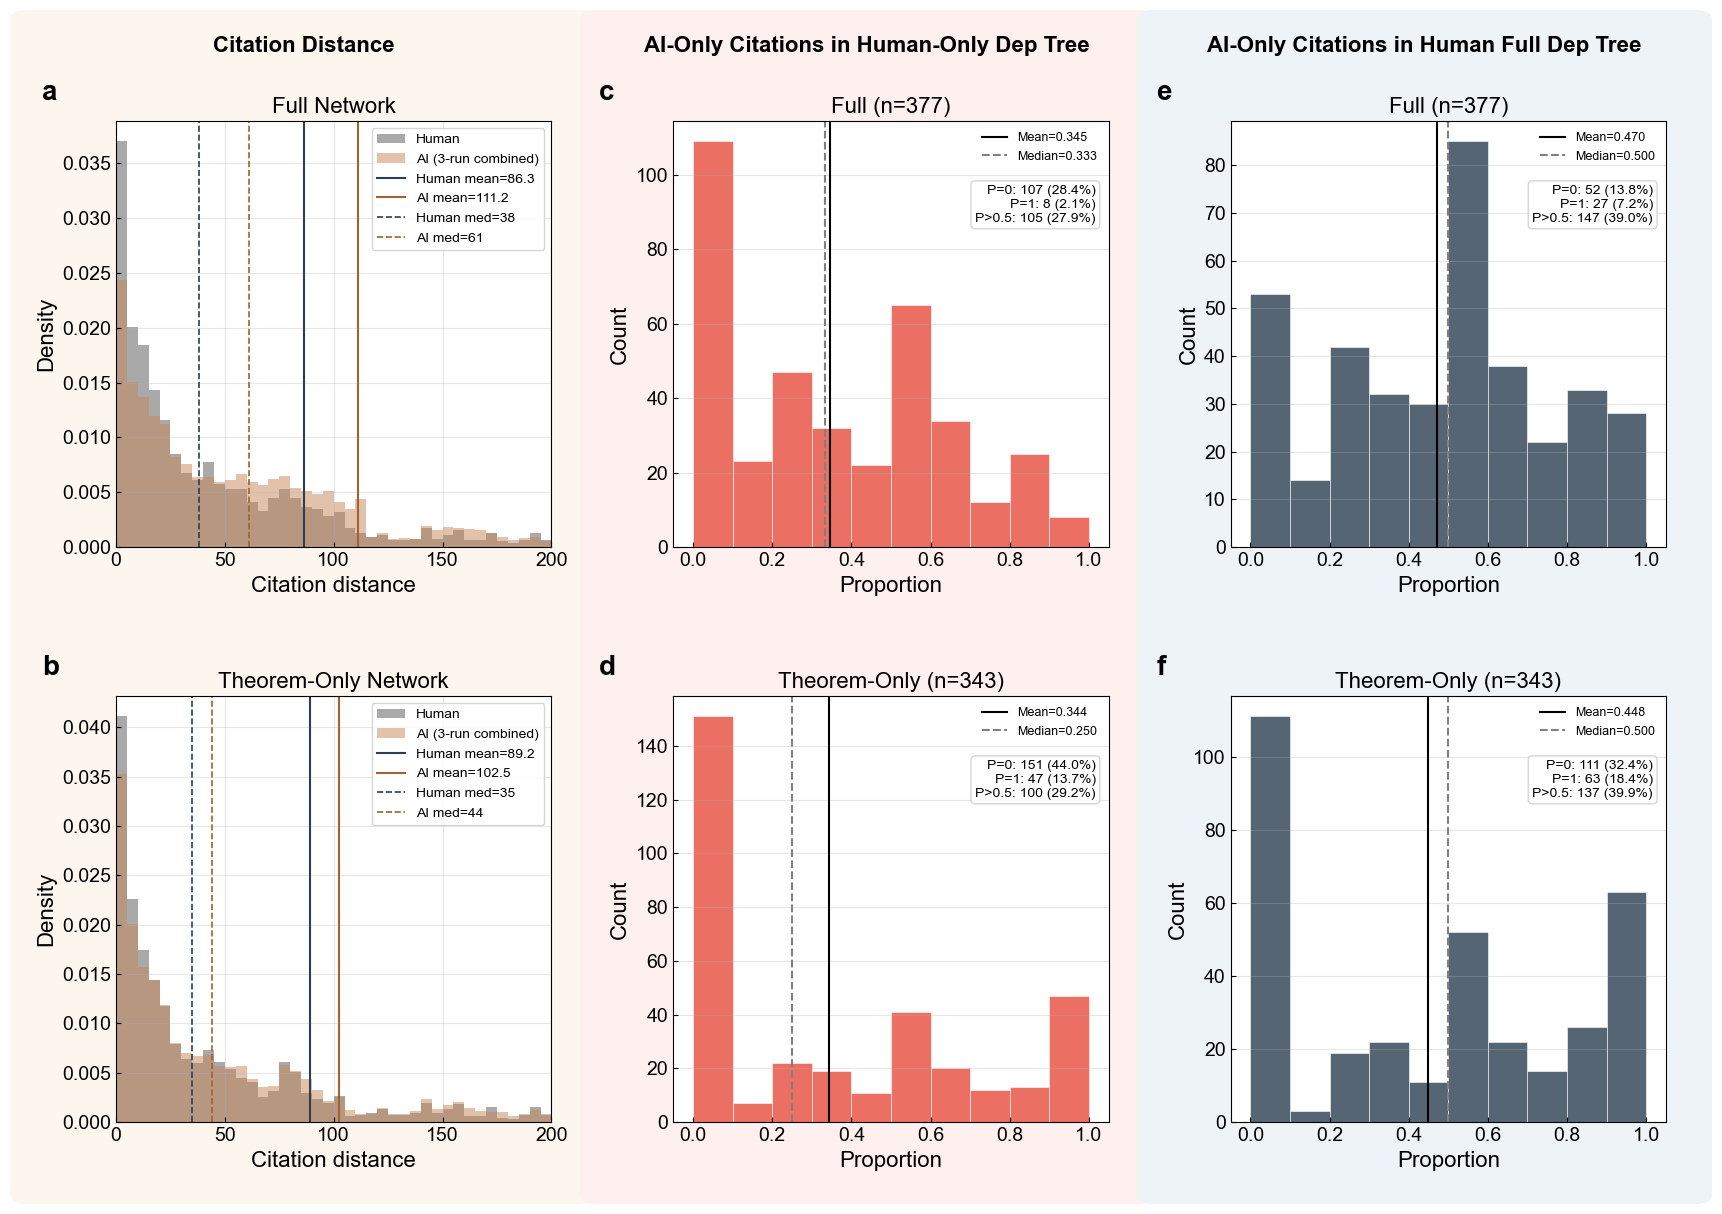

In [43]:
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.family'] = 'Arial'

fig, axes = plt.subplots(2, 3, figsize=(20, 13))

def plot_dist(ax, hu, ai, title, panel):
    bins = np.arange(0, 205, 5)
    ax.hist(hu, bins=bins, density=True, alpha=0.5, color='#555555',
            edgecolor='none', label='Human')
    ax.hist(ai, bins=bins, density=True, alpha=0.5, color='#c8875a',
            edgecolor='none', label='AI (3-run combined)')
    hm, am = np.mean(hu), np.mean(ai)
    hd, ad = np.median(hu), np.median(ai)
    ax.axvline(hm, color='#2c3e50', lw=1.5, label=f'Human mean={hm:.1f}')
    ax.axvline(am, color='#a0622e', lw=1.5, label=f'AI mean={am:.1f}')
    ax.axvline(hd, color='#2c3e50', lw=1.2, ls='--', label=f'Human med={hd:.0f}')
    ax.axvline(ad, color='#a0622e', lw=1.2, ls='--', label=f'AI med={ad:.0f}')
    ax.set_xlabel('Citation distance', fontsize=16)
    ax.set_ylabel('Density', fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(fontsize=10, loc='upper right')
    ax.set_xlim(0, 200)
    ax.grid(alpha=0.3)
    ax.text(-0.17, 1.05, panel, transform=ax.transAxes,
            fontsize=20, fontweight='bold')

def plot_prop(ax, vals, title, panel, color='#e74c3c'):
    bins = np.arange(0, 1.1, 0.1)
    ax.hist(vals, bins=bins, color=color, alpha=0.8,
            edgecolor='white', linewidth=0.5)
    m, md = vals.mean(), vals.median()
    ax.axvline(m,  color='black', ls='-',  lw=1.5, label=f'Mean={m:.3f}')
    ax.axvline(md, color='gray',  ls='--', lw=1.5, label=f'Median={md:.3f}')
    n  = len(vals)
    n0 = (vals == 0).sum()
    n1 = (vals == 1).sum()
    n05 = (vals > 0.5).sum()
    ax.text(0.97, 0.85,
            f'P=0: {n0} ({n0/n*100:.1f}%)\nP=1: {n1} ({n1/n*100:.1f}%)\nP>0.5: {n05} ({n05/n*100:.1f}%)',
            transform=ax.transAxes, fontsize=10, ha='right', va='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.8, edgecolor='#ccc'))
    ax.set_xlabel('Proportion', fontsize=16)
    ax.set_ylabel('Count', fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(fontsize=9, frameon=False)
    ax.grid(axis='y', alpha=0.3)
    ax.text(-0.17, 1.05, panel, transform=ax.transAxes,
            fontsize=20, fontweight='bold')

# Row 1: Full Network
plot_dist(axes[0, 0], hu_dist_full, ai_dist_full, 'Full Network', 'a')
plot_prop(axes[0, 1], df_prop_full['r_huonly'],
          f'Full (n={len(df_prop_full)})', 'c', '#e74c3c')
plot_prop(axes[0, 2], df_prop_full['r_full'],
          f'Full (n={len(df_prop_full)})', 'e', '#2c3e50')

# Row 2: Theorem-Only
plot_dist(axes[1, 0], hu_dist_thm, ai_dist_thm, 'Theorem-Only Network', 'b')
plot_prop(axes[1, 1], df_prop_thm['r_huonly'],
          f'Theorem-Only (n={len(df_prop_thm)})', 'd', '#e74c3c')
plot_prop(axes[1, 2], df_prop_thm['r_full'],
          f'Theorem-Only (n={len(df_prop_thm)})', 'f', '#2c3e50')

plt.subplots_adjust(hspace=0.35, wspace=0.28, top=0.88)

# 面板背景 + 标题
fig.canvas.draw()

col_colors  = ['#fdf6ee', '#fdf0ef', '#eef3f8']
panel_titles = [
    'Citation Distance',
    'AI-Only Citations in Human-Only Dep Tree',
    'AI-Only Citations in Human Full Dep Tree',
]
pad = 0.015
for col in range(3):
    ax_top = axes[0, col]
    ax_bot = axes[1, col]
    if col != 2:
        x0 = ax_top.get_position().x0 - pad - 0.03 + col * 0.006
    else:
        x0 = ax_top.get_position().x0 - pad - 0.03 + col * 0.003
    x1 = ax_top.get_position().x1 + pad
    y0 = ax_bot.get_position().y0 - pad - 0.04
    y1 = ax_top.get_position().y1 + pad * 2.5
    rect = mpatches.FancyBboxPatch(
        (x0, y0), x1 - x0, y1 - y0 + 0.04,
        transform=fig.transFigure, facecolor=col_colors[col],
        edgecolor='none', zorder=-1,
        boxstyle='round,pad=0.008')
    fig.add_artist(rect)
    fig.text((x0 + x1) / 2, y1 + 0.02, panel_titles[col],
             ha='center', va='center', fontsize=16, fontweight='bold')

#plt.savefig('E:/AI证明与人类证明的差异/Opus4.6正式实验/分析结果/figure3.pdf', dpi=200, bbox_inches='tight')
plt.show()

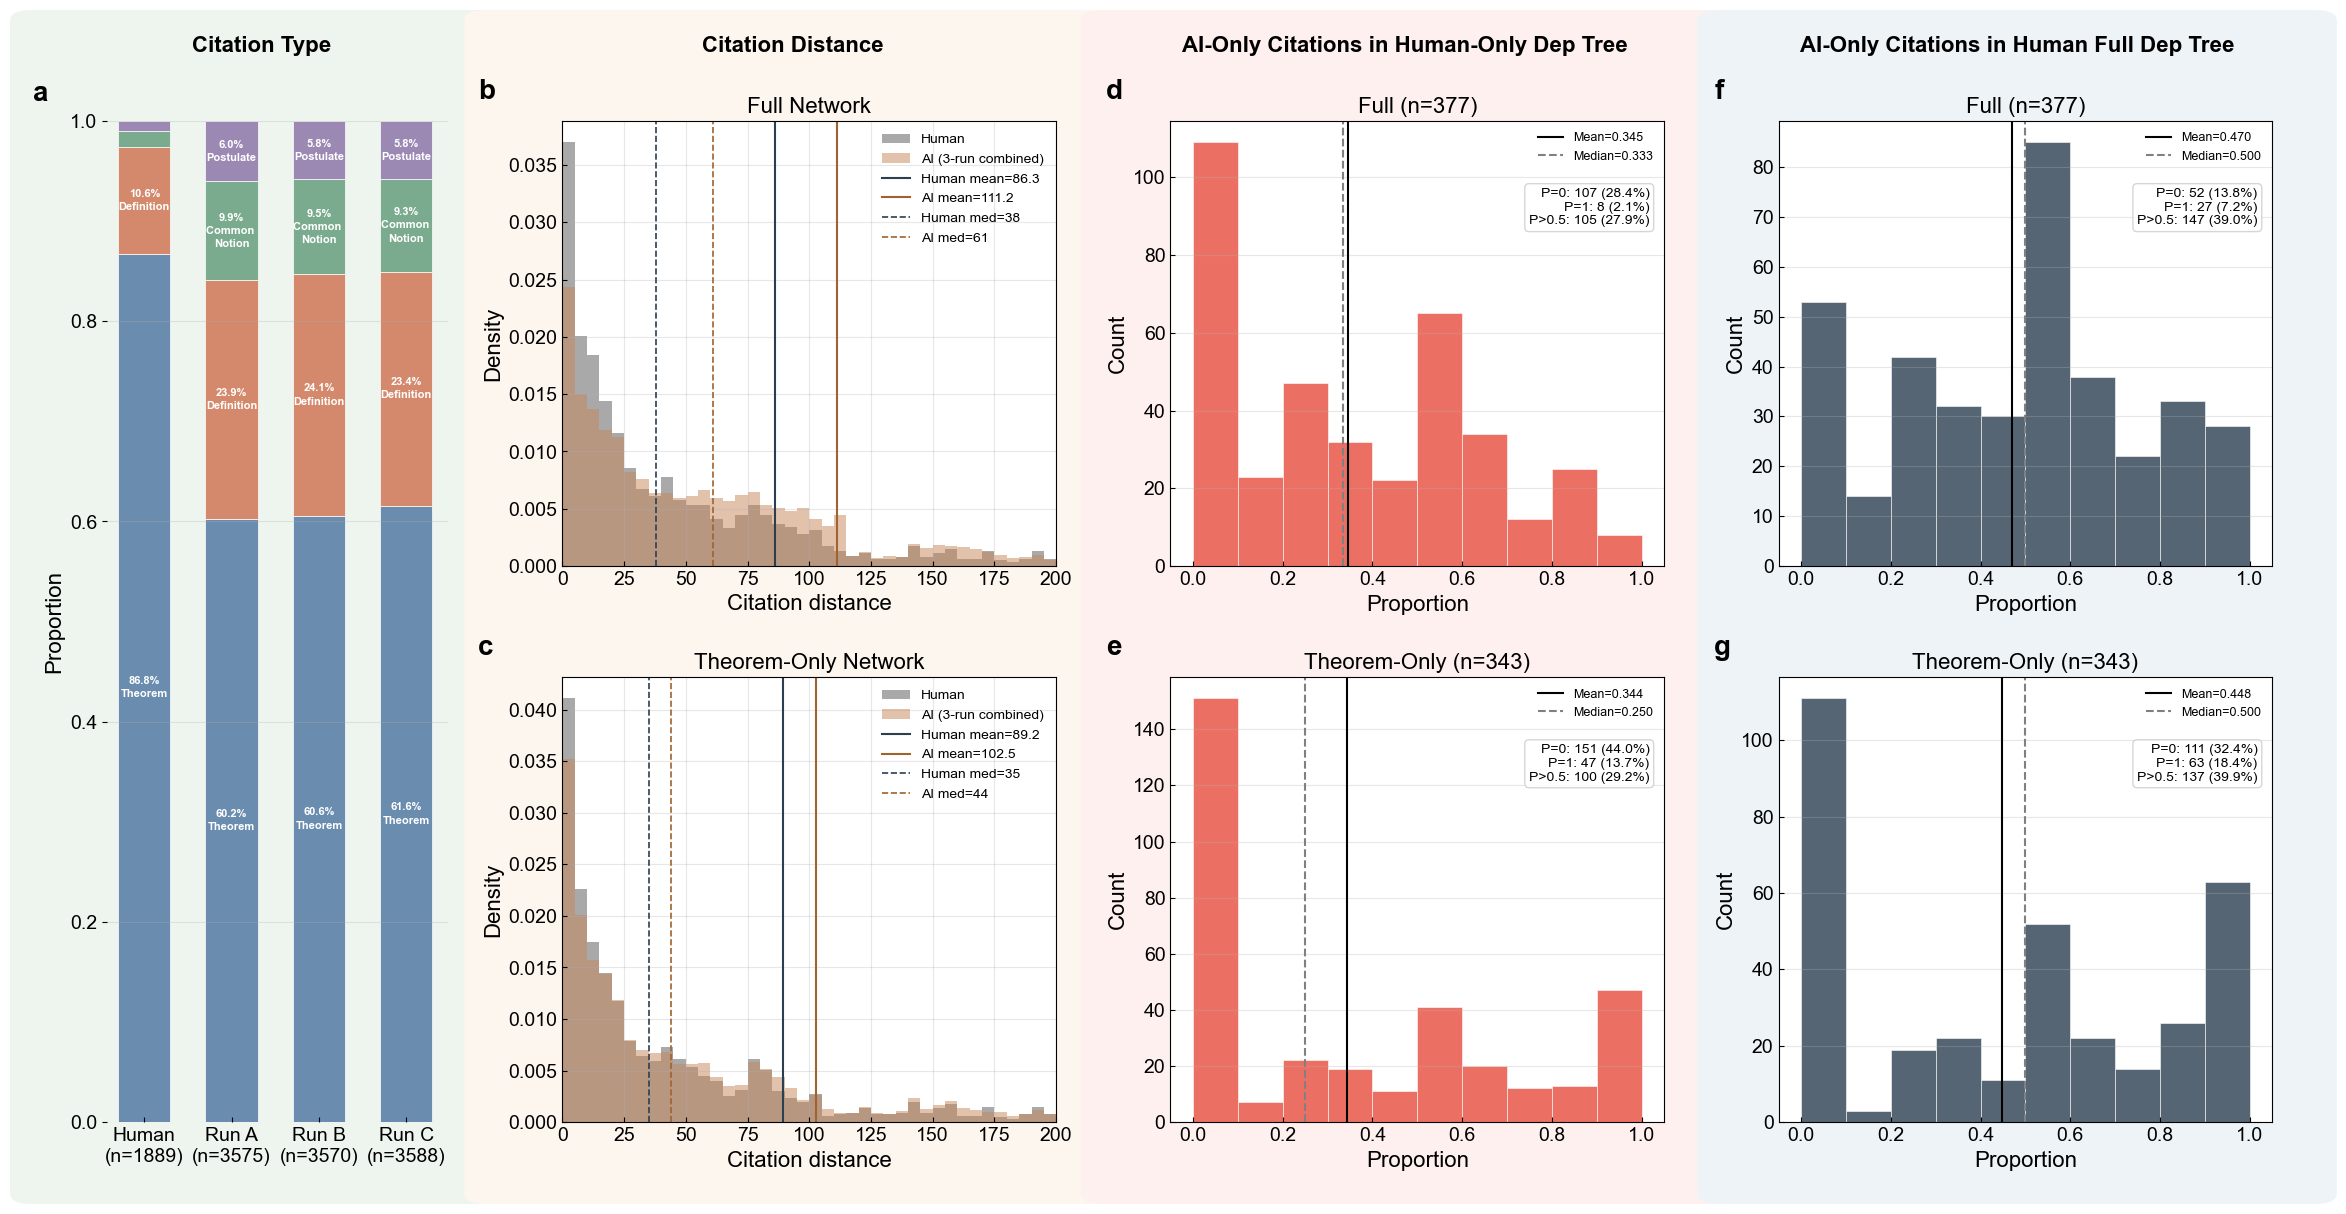

In [35]:
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.family'] = 'Arial'

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(28, 13))
gs = GridSpec(2, 4, width_ratios=[0.7, 1, 1, 1],
              hspace=0.25, wspace=0.25, top=0.88)

# 第一列跨两行
ax_type = fig.add_subplot(gs[:, 0])

# 其余三列各两行
axes = np.empty((2, 3), dtype=object)
for r in range(2):
    for c in range(3):
        axes[r, c] = fig.add_subplot(gs[r, c + 1])

# ====== (a) 引用类型堆叠柱状图 ======
def classify_ref(ref):
    ref = str(ref).strip()
    if re.fullmatch(r'P\d+', ref):
        return 'Postulate'
    elif ref.startswith('CN'):
        return 'Common \nNotion'
    elif ref.startswith('D'):
        return 'Definition'
    elif re.fullmatch(r'\d+\.\d+', ref):
        return 'Theorem'
    return 'Other'

def ref_type_stats(G):
    types = {'Theorem': 0, 'Definition': 0, 'Common \nNotion': 0, 'Postulate': 0}
    for u, v in G.edges():
        t = classify_ref(v)
        if t in types:
            types[t] += 1
    total = sum(types.values())
    return {k: v / total for k, v in types.items()} if total > 0 else types, total

def plot_dist(ax, hu, ai, title, panel):
    bins = np.arange(0, 205, 5)
    ax.hist(hu, bins=bins, density=True, alpha=0.5, color='#555555',
            edgecolor='none', label='Human')
    ax.hist(ai, bins=bins, density=True, alpha=0.5, color='#c8875a',
            edgecolor='none', label='AI (3-run combined)')
    hm, am = np.mean(hu), np.mean(ai)
    hd, ad = np.median(hu), np.median(ai)
    ax.axvline(hm, color='#2c3e50', lw=1.5, label=f'Human mean={hm:.1f}')
    ax.axvline(am, color='#a0622e', lw=1.5, label=f'AI mean={am:.1f}')
    ax.axvline(hd, color='#2c3e50', lw=1.2, ls='--', label=f'Human med={hd:.0f}')
    ax.axvline(ad, color='#a0622e', lw=1.2, ls='--', label=f'AI med={ad:.0f}')
    ax.set_xlabel('Citation distance', fontsize=16)
    ax.set_ylabel('Density', fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(fontsize=10, loc='upper right', frameon=False)
    ax.set_xlim(0, 200)
    ax.grid(alpha=0.3)
    ax.text(-0.17, 1.05, panel, transform=ax.transAxes,
            fontsize=20, fontweight='bold')

def plot_prop(ax, vals, title, panel, color='#e74c3c'):
    bins = np.arange(0, 1.1, 0.1)
    ax.hist(vals, bins=bins, color=color, alpha=0.8,
            edgecolor='white', linewidth=0.5)
    m, md = vals.mean(), vals.median()
    ax.axvline(m,  color='black', ls='-',  lw=1.5, label=f'Mean={m:.3f}')
    ax.axvline(md, color='gray',  ls='--', lw=1.5, label=f'Median={md:.3f}')
    n  = len(vals)
    n0 = (vals == 0).sum()
    n1 = (vals == 1).sum()
    n05 = (vals > 0.5).sum()
    ax.text(0.97, 0.85,
            f'P=0: {n0} ({n0/n*100:.1f}%)\nP=1: {n1} ({n1/n*100:.1f}%)\nP>0.5: {n05} ({n05/n*100:.1f}%)',
            transform=ax.transAxes, fontsize=10, ha='right', va='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.8, edgecolor='#ccc'))
    ax.set_xlabel('Proportion', fontsize=16)
    ax.set_ylabel('Count', fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(fontsize=9, frameon=False)
    ax.grid(axis='y', alpha=0.3)
    ax.text(-0.13, 1.05, panel, transform=ax.transAxes,
            fontsize=20, fontweight='bold')

stats = {'Human': ref_type_stats(G_hu_full)}
for run in ['RunA', 'RunB', 'RunC']:
    stats[run] = ref_type_stats(G_ai_full[run])

ref_types = ['Theorem', 'Definition', 'Common \nNotion', 'Postulate']
type_colors = {'Theorem': '#6a8caf', 'Definition': '#d4896c',
               'Common \nNotion': '#7bab8e', 'Postulate': '#9b89b4'}
bar_keys  = ['Human', 'RunA', 'RunB', 'RunC']
bar_names = ['Human', 'Run A', 'Run B', 'Run C']

x = np.arange(len(bar_names))
bottoms = np.zeros(len(bar_names))
for rt in ref_types:
    vals = np.array([stats[k][0][rt] for k in bar_keys])
    ax_type.bar(x, vals, bottom=bottoms, color=type_colors[rt],
                edgecolor='white', linewidth=0.5, width=0.6)
    for i, (v, b) in enumerate(zip(vals, bottoms)):
        if v > 0.055:
            ax_type.text(i, b + v / 2, f'{v * 100:.1f}%\n{rt}',
                         ha='center', va='center', fontsize=8,
                         color='white', fontweight='bold', linespacing=1.4)
        elif v > 0.03:
            ax_type.text(i, b + v / 2, f'{v * 100:.1f}%',
                         ha='center', va='center', fontsize=8,
                         color='white', fontweight='bold')
    bottoms += vals

xlabels = [f'{nm}\n(n={stats[k][1]})' for nm, k in zip(bar_names, bar_keys)]
ax_type.set_xticks(x)
ax_type.set_xticklabels(xlabels, fontsize=14)
ax_type.set_ylabel('Proportion', fontsize=16)
ax_type.set_ylim(0, 1)
ax_type.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax_type.tick_params(axis='y', labelsize=14)
ax_type.set_facecolor('none')
for spine in ax_type.spines.values():
    spine.set_visible(False)
ax_type.grid(axis='y', alpha=0.3)
ax_type.text(-0.2, 1.02, 'a', transform=ax_type.transAxes,
             fontsize=20, fontweight='bold')

# Row 1: Full Network — 编号 b, d, f
plot_dist(axes[0, 0], hu_dist_full, ai_dist_full, 'Full Network', 'b')
plot_prop(axes[0, 1], df_prop_full['r_huonly'],
          f'Full (n={len(df_prop_full)})', 'd', '#e74c3c')
plot_prop(axes[0, 2], df_prop_full['r_full'],
          f'Full (n={len(df_prop_full)})', 'f', '#2c3e50')

# Row 2: Theorem-Only — 编号 c, e, g
plot_dist(axes[1, 0], hu_dist_thm, ai_dist_thm, 'Theorem-Only Network', 'c')
plot_prop(axes[1, 1], df_prop_thm['r_huonly'],
          f'Theorem-Only (n={len(df_prop_thm)})', 'e', '#e74c3c')
plot_prop(axes[1, 2], df_prop_thm['r_full'],
          f'Theorem-Only (n={len(df_prop_thm)})', 'g', '#2c3e50')

fig.canvas.draw()

col_colors  = ['#eef5ee', '#fdf6ee', '#fdf0ef', '#eef3f8']
panel_titles = [
    'Citation Type',
    'Citation Distance',
    'AI-Only Citations in Human-Only Dep Tree',
    'AI-Only Citations in Human Full Dep Tree',
]
pad = 0.015

# Col 0: 跨两行，用 ax_type 的位置
pos = ax_type.get_position()
x0, x1 = pos.x0 - pad - 0.01, pos.x1 + pad
y0 = pos.y0 - pad - 0.04
y1 = pos.y1 + pad * 2.5
rect = mpatches.FancyBboxPatch(
    (x0, y0), x1 - x0, y1 - y0 + 0.04,
    transform=fig.transFigure, facecolor=col_colors[0],
    edgecolor='none', zorder=-1, boxstyle='round,pad=0.008')
fig.add_artist(rect)
fig.text((x0 + x1) / 2, y1 + 0.02, panel_titles[0],
         ha='center', va='center', fontsize=16, fontweight='bold')

# Cols 1-3: 沿用你原来的逻辑
for col in range(3):
    ax_top = axes[0, col]
    ax_bot = axes[1, col]
    if col != 2:
        bx0 = ax_top.get_position().x0 - pad - 0.012 + col * 0.003
    else:
        bx0 = ax_top.get_position().x0 - pad - 0.012 + col * 0.003
    bx1 = ax_top.get_position().x1 + pad
    by0 = ax_bot.get_position().y0 - pad - 0.04
    by1 = ax_top.get_position().y1 + pad * 2.5
    rect = mpatches.FancyBboxPatch(
        (bx0, by0), bx1 - bx0, by1 - by0 + 0.04,
        transform=fig.transFigure, facecolor=col_colors[col + 1],
        edgecolor='none', zorder=-1, boxstyle='round,pad=0.008')
    fig.add_artist(rect)
    fig.text((bx0 + bx1) / 2, by1 + 0.02, panel_titles[col + 1],
             ha='center', va='center', fontsize=16, fontweight='bold')

#plt.savefig('E:/AI证明与人类证明的差异/Opus4.6正式实验/分析结果/figure3.pdf', dpi=300, bbox_inches='tight')
plt.show()

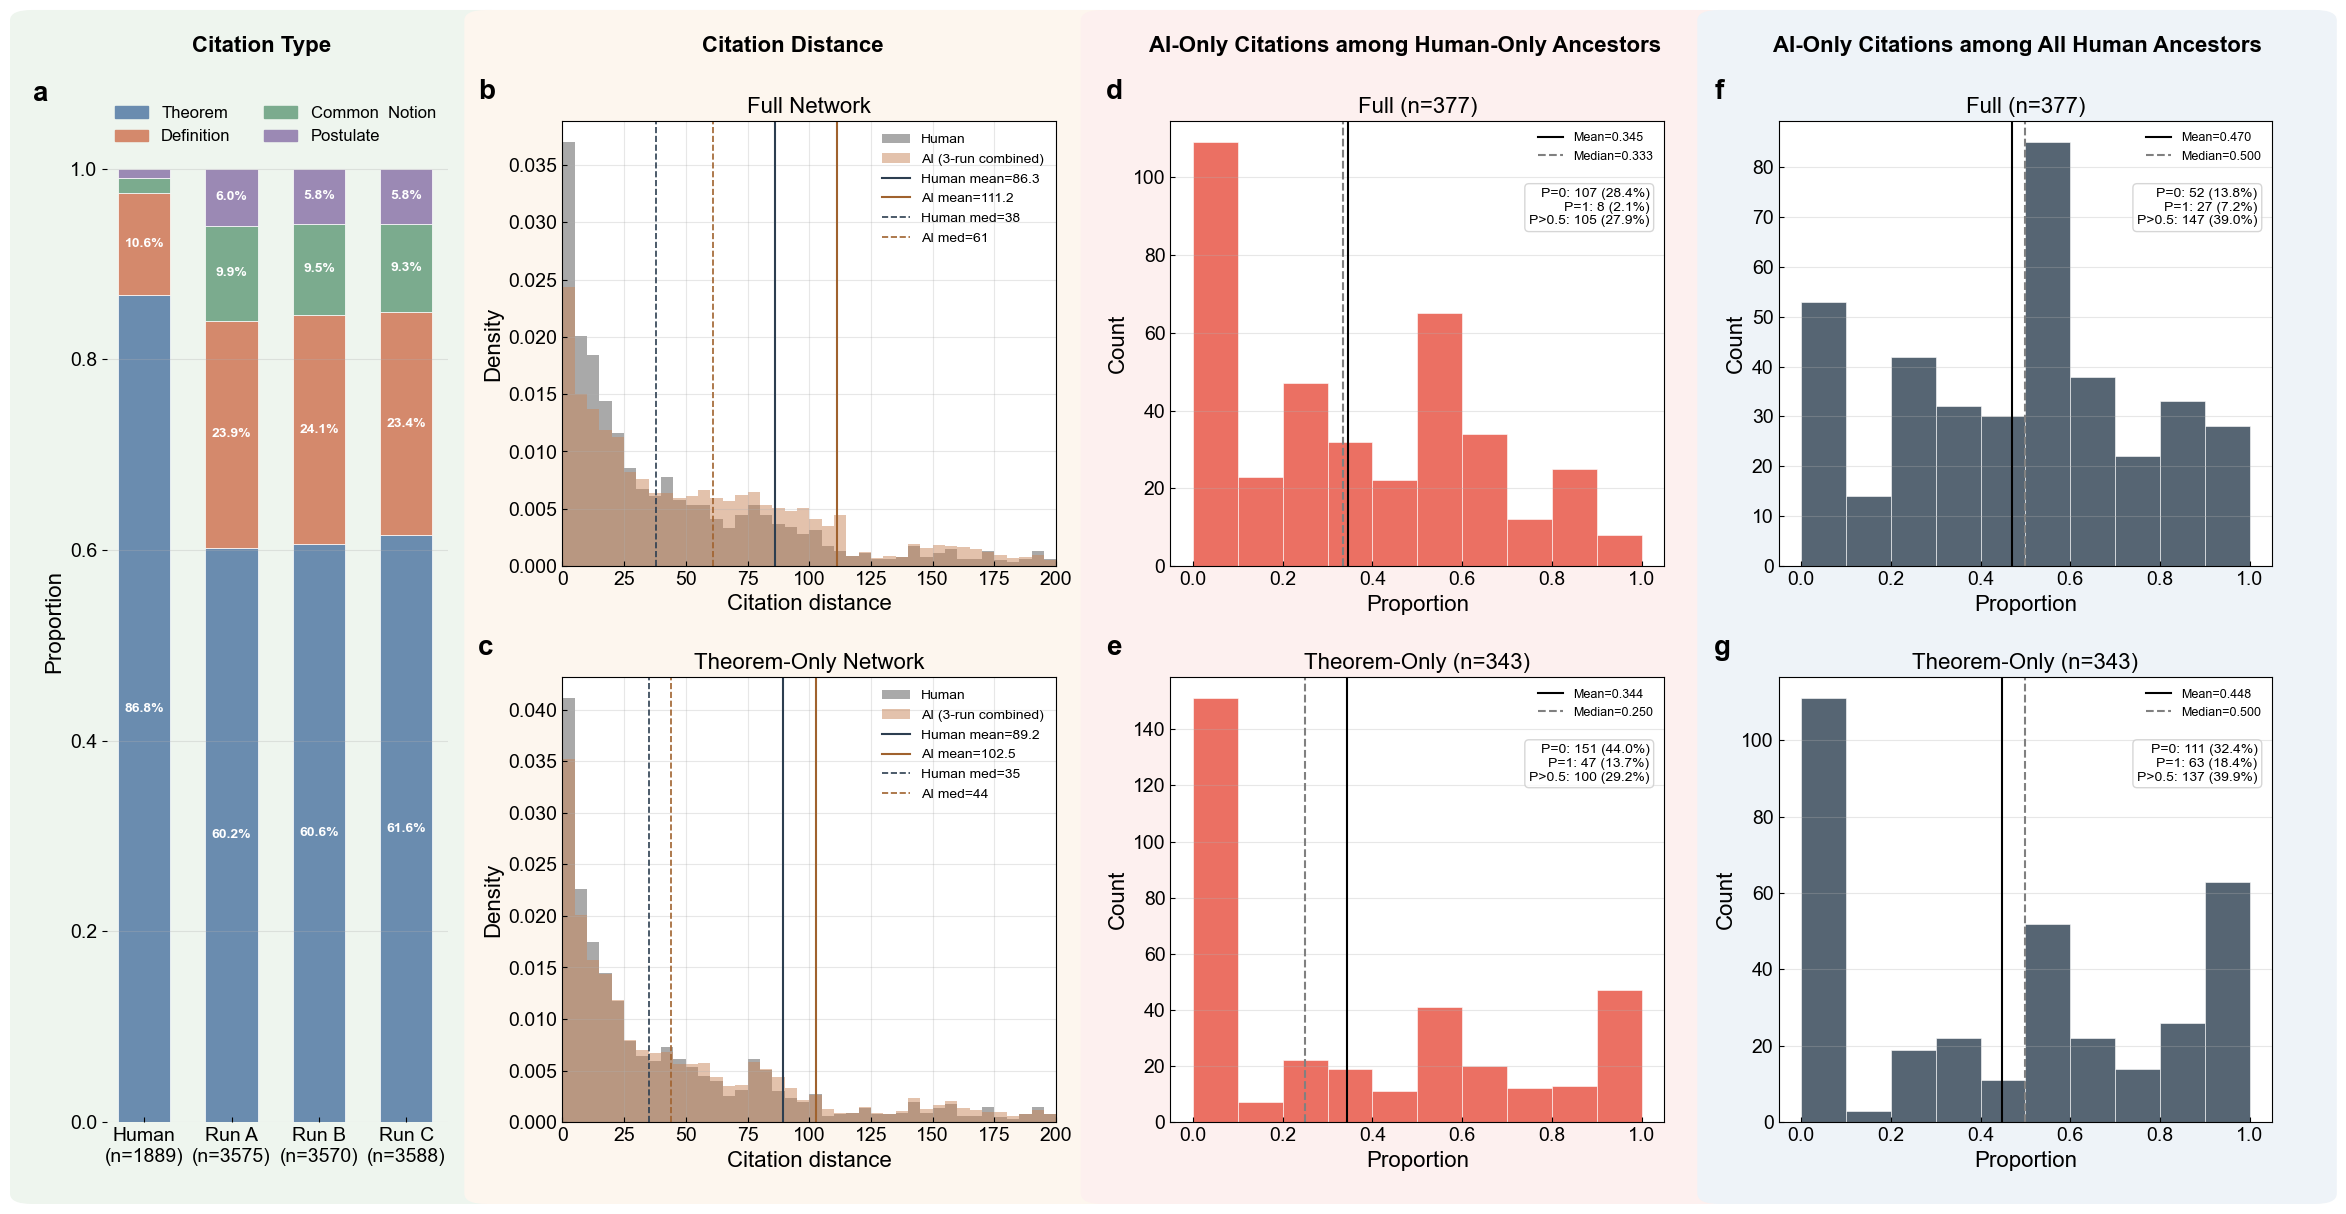

In [18]:
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.family'] = 'Arial'

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(28, 13))
gs = GridSpec(2, 4, width_ratios=[0.7, 1, 1, 1],
              hspace=0.25, wspace=0.25, top=0.88)

# 第一列跨两行
ax_type = fig.add_subplot(gs[:, 0])

# 其余三列各两行
axes = np.empty((2, 3), dtype=object)
for r in range(2):
    for c in range(3):
        axes[r, c] = fig.add_subplot(gs[r, c + 1])

# ====== (a) 引用类型堆叠柱状图 ======
def classify_ref(ref):
    ref = str(ref).strip()
    if re.fullmatch(r'P\d+', ref):
        return 'Postulate'
    elif ref.startswith('CN'):
        return 'Common \nNotion'
    elif ref.startswith('D'):
        return 'Definition'
    elif re.fullmatch(r'\d+\.\d+', ref):
        return 'Theorem'
    return 'Other'

def ref_type_stats(G):
    types = {'Theorem': 0, 'Definition': 0, 'Common \nNotion': 0, 'Postulate': 0}
    for u, v in G.edges():
        t = classify_ref(v)
        if t in types:
            types[t] += 1
    total = sum(types.values())
    return {k: v / total for k, v in types.items()} if total > 0 else types, total

def plot_dist(ax, hu, ai, title, panel):
    bins = np.arange(0, 205, 5)
    ax.hist(hu, bins=bins, density=True, alpha=0.5, color='#555555',
            edgecolor='none', label='Human')
    ax.hist(ai, bins=bins, density=True, alpha=0.5, color='#c8875a',
            edgecolor='none', label='AI (3-run combined)')
    hm, am = np.mean(hu), np.mean(ai)
    hd, ad = np.median(hu), np.median(ai)
    ax.axvline(hm, color='#2c3e50', lw=1.5, label=f'Human mean={hm:.1f}')
    ax.axvline(am, color='#a0622e', lw=1.5, label=f'AI mean={am:.1f}')
    ax.axvline(hd, color='#2c3e50', lw=1.2, ls='--', label=f'Human med={hd:.0f}')
    ax.axvline(ad, color='#a0622e', lw=1.2, ls='--', label=f'AI med={ad:.0f}')
    ax.set_xlabel('Citation distance', fontsize=16)
    ax.set_ylabel('Density', fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(fontsize=10, loc='upper right', frameon=False)
    ax.set_xlim(0, 200)
    ax.grid(alpha=0.3)
    ax.text(-0.17, 1.05, panel, transform=ax.transAxes,
            fontsize=20, fontweight='bold')

def plot_prop(ax, vals, title, panel, color='#e74c3c'):
    bins = np.arange(0, 1.1, 0.1)
    ax.hist(vals, bins=bins, color=color, alpha=0.8,
            edgecolor='white', linewidth=0.5)
    m, md = vals.mean(), vals.median()
    ax.axvline(m,  color='black', ls='-',  lw=1.5, label=f'Mean={m:.3f}')
    ax.axvline(md, color='gray',  ls='--', lw=1.5, label=f'Median={md:.3f}')
    n  = len(vals)
    n0 = (vals == 0).sum()
    n1 = (vals == 1).sum()
    n05 = (vals > 0.5).sum()
    ax.text(0.97, 0.85,
            f'P=0: {n0} ({n0/n*100:.1f}%)\nP=1: {n1} ({n1/n*100:.1f}%)\nP>0.5: {n05} ({n05/n*100:.1f}%)',
            transform=ax.transAxes, fontsize=10, ha='right', va='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      alpha=0.8, edgecolor='#ccc'))
    ax.set_xlabel('Proportion', fontsize=16)
    ax.set_ylabel('Count', fontsize=16)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(fontsize=9, frameon=False)
    ax.grid(axis='y', alpha=0.3)
    ax.text(-0.13, 1.05, panel, transform=ax.transAxes,
            fontsize=20, fontweight='bold')

stats = {'Human': ref_type_stats(G_hu_full)}
for run in ['RunA', 'RunB', 'RunC']:
    stats[run] = ref_type_stats(G_ai_full[run])

ref_types = ['Theorem', 'Definition', 'Common \nNotion', 'Postulate']
type_colors = {'Theorem': '#6a8caf', 'Definition': '#d4896c',
               'Common \nNotion': '#7bab8e', 'Postulate': '#9b89b4'}
bar_keys  = ['Human', 'RunA', 'RunB', 'RunC']
bar_names = ['Human', 'Run A', 'Run B', 'Run C']

# ====== 柱子内只写百分比 ======
x = np.arange(len(bar_names))
bottoms = np.zeros(len(bar_names))
for rt in ref_types:
    vals = np.array([stats[k][0][rt] for k in bar_keys])
    ax_type.bar(x, vals, bottom=bottoms, color=type_colors[rt],
                edgecolor='white', linewidth=0.5, width=0.6)
    for i, (v, b) in enumerate(zip(vals, bottoms)):
        if v > 0.03:
            ax_type.text(i, b + v / 2, f'{v * 100:.1f}%',
                         ha='center', va='center', fontsize=10,
                         color='white', fontweight='bold')
    bottoms += vals

xlabels = [f'{nm}\n(n={stats[k][1]})' for nm, k in zip(bar_names, bar_keys)]
ax_type.set_xticks(x)
ax_type.set_xticklabels(xlabels, fontsize=14)
ax_type.set_ylabel('Proportion', fontsize=16)
ax_type.set_ylim(0, 1.05)
ax_type.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax_type.tick_params(axis='y', labelsize=14)
ax_type.set_facecolor('none')
for spine in ax_type.spines.values():
    spine.set_visible(False)
ax_type.grid(axis='y', alpha=0.3)
ax_type.text(-0.2, 1.02, 'a', transform=ax_type.transAxes,
             fontsize=20, fontweight='bold')

# ====== 图例放在柱子上方 ======
legend_patches = [mpatches.Patch(color=type_colors[rt], label=rt.replace('\n', ' '))
                  for rt in ref_types]
ax_type.legend(handles=legend_patches, loc='upper center',bbox_to_anchor=(0.5, 1.03),
               fontsize=12, ncol=2, frameon=False)

# Row 1: Full Network — 编号 b, d, f
plot_dist(axes[0, 0], hu_dist_full, ai_dist_full, 'Full Network', 'b')
plot_prop(axes[0, 1], df_prop_full['r_huonly'],
          f'Full (n={len(df_prop_full)})', 'd', '#e74c3c')
plot_prop(axes[0, 2], df_prop_full['r_full'],
          f'Full (n={len(df_prop_full)})', 'f', '#2c3e50')

# Row 2: Theorem-Only — 编号 c, e, g
plot_dist(axes[1, 0], hu_dist_thm, ai_dist_thm, 'Theorem-Only Network', 'c')
plot_prop(axes[1, 1], df_prop_thm['r_huonly'],
          f'Theorem-Only (n={len(df_prop_thm)})', 'e', '#e74c3c')
plot_prop(axes[1, 2], df_prop_thm['r_full'],
          f'Theorem-Only (n={len(df_prop_thm)})', 'g', '#2c3e50')

fig.canvas.draw()

col_colors  = ['#eef5ee', '#fdf6ee', '#fdf0ef', '#eef3f8']
panel_titles = [
    'Citation Type',
    'Citation Distance',
    'AI-Only Citations among Human-Only Ancestors',
    'AI-Only Citations among All Human Ancestors',
]
pad = 0.015

# Col 0: 跨两行，用 ax_type 的位置
pos = ax_type.get_position()
x0, x1 = pos.x0 - pad - 0.01, pos.x1 + pad
y0 = pos.y0 - pad - 0.04
y1 = pos.y1 + pad * 2.5
rect = mpatches.FancyBboxPatch(
    (x0, y0), x1 - x0, y1 - y0 + 0.04,
    transform=fig.transFigure, facecolor=col_colors[0],
    edgecolor='none', zorder=-1, boxstyle='round,pad=0.008')
fig.add_artist(rect)
fig.text((x0 + x1) / 2, y1 + 0.02, panel_titles[0],
         ha='center', va='center', fontsize=16, fontweight='bold')

# Cols 1-3: 沿用你原来的逻辑
for col in range(3):
    ax_top = axes[0, col]
    ax_bot = axes[1, col]
    if col != 2:
        bx0 = ax_top.get_position().x0 - pad - 0.012 + col * 0.003
    else:
        bx0 = ax_top.get_position().x0 - pad - 0.012 + col * 0.003
    bx1 = ax_top.get_position().x1 + pad
    by0 = ax_bot.get_position().y0 - pad - 0.04
    by1 = ax_top.get_position().y1 + pad * 2.5
    rect = mpatches.FancyBboxPatch(
        (bx0, by0), bx1 - bx0, by1 - by0 + 0.04,
        transform=fig.transFigure, facecolor=col_colors[col + 1],
        edgecolor='none', zorder=-1, boxstyle='round,pad=0.008')
    fig.add_artist(rect)
    fig.text((bx0 + bx1) / 2, by1 + 0.02, panel_titles[col + 1],
             ha='center', va='center', fontsize=16, fontweight='bold')

#plt.savefig('E:/AI证明与人类证明的差异/Opus4.6正式实验/分析结果/figure3.pdf', dpi=300, bbox_inches='tight')
plt.show()